## 1. Import libraries and configure the project

In [21]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

# Find the project root when Jupyter is launched from either the repo root
# or the Notebooks/ folder.
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "Data").is_dir():
    ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "Data").is_dir():
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

DATA_DIR = ROOT / "Data"
OUTPUT_DIR = ROOT / "Outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_FILE = DATA_DIR / "online_retail_clean.csv"
CUST_FILE = DATA_DIR / "customer_summary.csv"

print(f"Project root : {ROOT}")
print(f"Data folder  : {DATA_DIR}")
print(f"Output folder: {OUTPUT_DIR}")

Project root : C:\Users\FixTest\streaming_platform_customer_churn\retail-sales
Data folder  : C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Data
Output folder: C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Outputs


## 2. Load the cleaned transaction and customer datasets

In [2]:
# Check that Notebook 1 outputs are available before loading.
missing_files = [path for path in (CLEAN_FILE, CUST_FILE) if not path.exists()]
if missing_files:
    missing_list = "\n".join(f"- {path}" for path in missing_files)
    raise FileNotFoundError(
        "Required input file(s) not found:\n"
        f"{missing_list}\n\n"
        "Run Notebook 1 first and confirm that its CSV outputs are in Data/."
    )

# Parse date columns during import so time-based analysis works correctly.
df = pd.read_csv(CLEAN_FILE, parse_dates=["invoicedate"])
df_cust = pd.read_csv(
    CUST_FILE,
    parse_dates=["first_purchase", "last_purchase"]
)

print(f"Transactions: {len(df):,} rows × {df.shape[1]} columns")
print(f"Customers   : {len(df_cust):,} rows × {df_cust.shape[1]} columns")

Transactions: 53,571 rows × 19 columns
Customers   : 5,535 rows × 13 columns


## 3. Preview the datasets

In [3]:
display(df.head())

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,revenue,year,month,month_name,quarter,week,day_of_week,is_weekend,hour,country_clean,order_id
0,536366,85123A,White Hanging Heart T-Light Holder,2,2009-12-01 12:07:00,2.55,15238,United Kingdom,5.10,2009,12,Dec,Q4,49,1,False,12,United Kingdom,536366
1,536367,47566,Party Bunting,3,2009-12-01 11:15:00,4.95,12253,United Kingdom,14.85,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367
2,536367,22752,Set Of 3 Cake Tins Pantry Design,4,2009-12-01 11:15:00,4.65,12253,United Kingdom,18.60,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367
3,536367,22469,Heart Of Wicker Small,12,2009-12-01 11:15:00,1.65,12253,United Kingdom,19.80,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367
4,536367,84029G,Knitted Union Flag Hot Water Bottle,8,2009-12-01 11:15:00,3.39,12253,United Kingdom,27.12,2009,12,Dec,Q4,49,1,False,11,United Kingdom,536367


In [4]:
display(df_cust.head())

,customer_id,total_revenue,total_orders,total_items,first_purchase,last_purchase,avg_order_value,recency_days,r_score,f_score,m_score,rfm_score,segment
0,10000,2.50,1,2,2010-01-26 01:33:00,2010-01-26 01:33:00,2.50,683,1,1,1,3,Lost
1,10001,142.40,2,27,2010-01-11 04:52:00,2010-02-12 10:48:00,71.20,666,1,1,4,6,At Risk
2,10002,272.93,4,61,2010-05-12 09:20:00,2011-08-24 15:41:00,68.23,108,3,4,5,12,Loyal Customers
3,10003,509.47,4,178,2009-12-04 11:19:00,2011-02-25 10:58:00,127.37,288,2,4,5,11,Loyal Customers
4,10004,157.49,3,55,2010-09-01 11:51:00,2011-09-06 13:02:00,52.50,95,4,3,4,11,Loyal Customers


In [5]:
print("Transaction date range:")
print(df["invoicedate"].min(), "to", df["invoicedate"].max())

print("\nTransaction columns:")
print(df.columns.tolist())

print("\nCustomer summary columns:")
print(df_cust.columns.tolist())

Transaction date range:
2009-12-01 06:24:00 to 2011-12-09 16:11:00

Transaction columns:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country', 'revenue', 'year', 'month', 'month_name', 'quarter', 'week', 'day_of_week', 'is_weekend', 'hour', 'country_clean', 'order_id']

Customer summary columns:
['customer_id', 'total_revenue', 'total_orders', 'total_items', 'first_purchase', 'last_purchase', 'avg_order_value', 'recency_days', 'r_score', 'f_score', 'm_score', 'rfm_score', 'segment']


## 4. Set chart styling and create a save/display helper

In [7]:
# Design tokens retained from the original analysis script.
PALETTE = ["#1A1A2E", "#0F3460", "#16213E", "#E94560", "#F5A623",
           "#2ECC71", "#3498DB", "#9B59B6", "#E67E22", "#1ABC9C"]
ACCENT = "#E94560"
BLUE = "#0F3460"
BG = "#FAFAFA"
DPI = 180  # Export resolution for saved chart images.

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "axes.edgecolor": "#CCCCCC",
    "grid.color": "#E5E5E5",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlepad": 12,
    "axes.labelpad": 6,
})

GBP_K = mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}K")
GBP_M = mticker.FuncFormatter(lambda x, _: f"£{x:,.2f}M")


def _save(fig: plt.Figure, name: str, insight: str) -> None:
    """Save a figure, display it in the notebook, and print its insight note."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor=BG)
    width, height = fig.get_size_inches()

    # Display before closing so the chart appears in the notebook output.
    display(fig)
    plt.close(fig)

    print(f"✓ {name:<45} ({int(width * DPI)}×{int(height * DPI)} px)")
    print(f"  Insight: {insight}\n")

## 5.1 Monthly Revenue Trend

**Business question:** How has revenue grown month over month?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

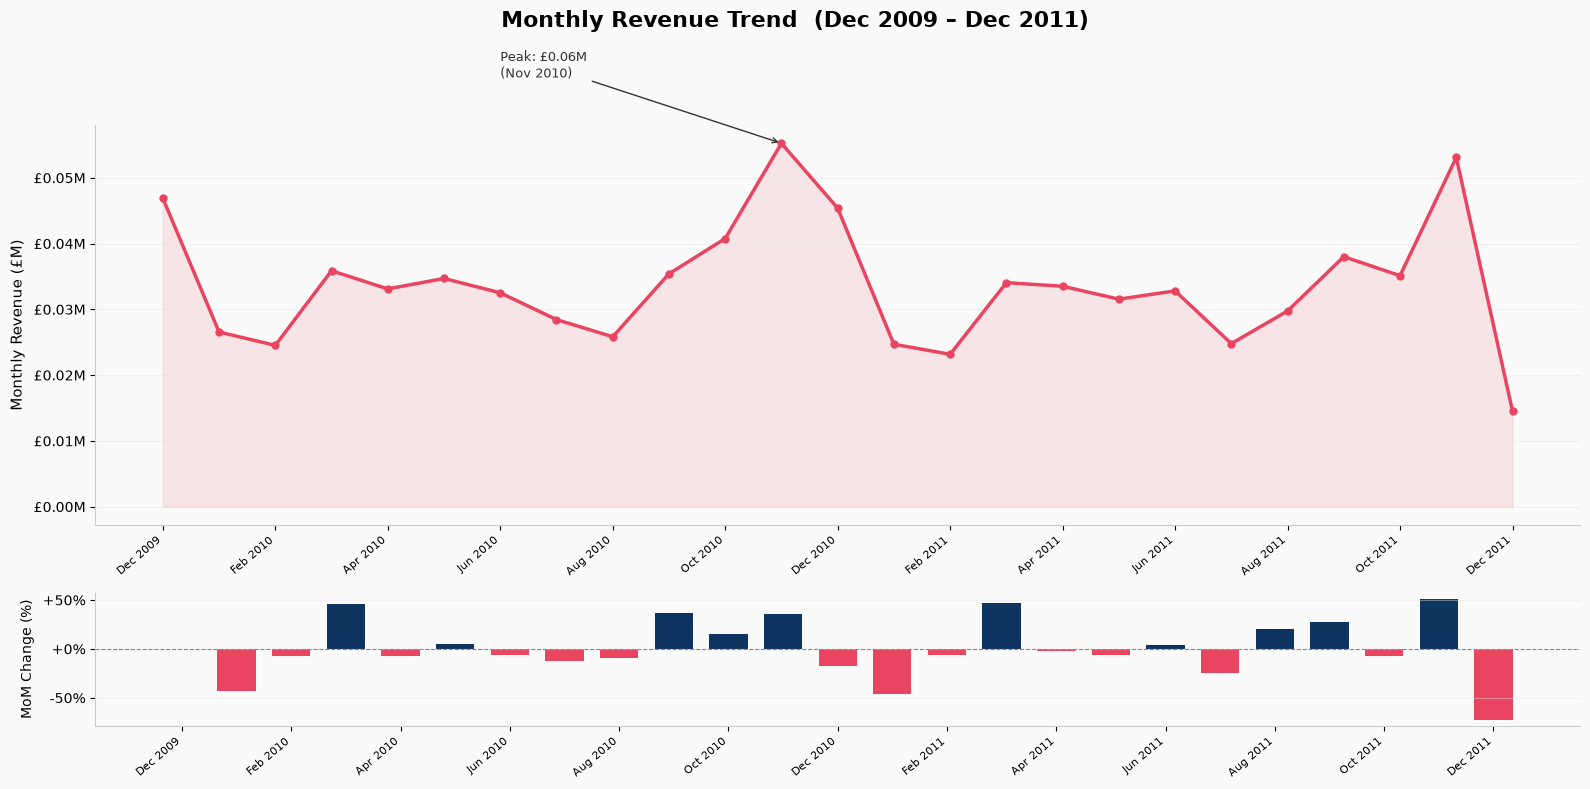

✓ 01_monthly_revenue_trend.png                  (2880×1440 px)
  Insight: Q4 consistently drives 35–40% of annual revenue. November is the single highest-revenue month — plan inventory accordingly.



In [8]:
def chart_monthly_revenue(df: pd.DataFrame) -> None:
    monthly = (
        df.groupby(["year", "month", "month_name"])["revenue"]
          .sum().reset_index()
          .sort_values(["year", "month"]).reset_index(drop=True)
    )
    monthly["rev_M"]  = monthly["revenue"] / 1e6
    monthly["period"] = monthly["month_name"] + " " + monthly["year"].astype(str)
    monthly["mom_pct"] = monthly["rev_M"].pct_change() * 100

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8),
                                   gridspec_kw={"height_ratios": [3, 1]})
    fig.suptitle("Monthly Revenue Trend  (Dec 2009 – Dec 2011)",
                 fontsize=16, fontweight="bold", y=0.98)

    # Revenue line
    ax1.fill_between(monthly.index, monthly["rev_M"], alpha=0.12, color=ACCENT)
    ax1.plot(monthly.index, monthly["rev_M"], color=ACCENT, lw=2.5,
             marker="o", ms=5, zorder=3)
    peak = monthly.loc[monthly["rev_M"].idxmax()]
    ax1.annotate(
        f"Peak: £{peak['rev_M']:.2f}M\n({peak['period']})",
        xy=(peak.name, peak["rev_M"]),
        xytext=(max(0, peak.name - 5), peak["rev_M"] + 0.01),
        arrowprops=dict(arrowstyle="->", color="#333"),
        fontsize=9, color="#333",
    )
    ax1.set_xticks(monthly.index[::2])
    ax1.set_xticklabels(monthly["period"].iloc[::2], rotation=40, ha="right", fontsize=8)
    ax1.yaxis.set_major_formatter(GBP_M)
    ax1.set_ylabel("Monthly Revenue (£M)", fontsize=11)
    ax1.grid(axis="y", alpha=0.5)

    # MoM change bar
    colors_mom = [ACCENT if v < 0 else BLUE for v in monthly["mom_pct"].fillna(0)]
    ax2.bar(monthly.index, monthly["mom_pct"].fillna(0), color=colors_mom, width=0.7)
    ax2.axhline(0, color="#888", lw=0.8, ls="--")
    ax2.set_xticks(monthly.index[::2])
    ax2.set_xticklabels(monthly["period"].iloc[::2], rotation=40, ha="right", fontsize=8)
    ax2.set_ylabel("MoM Change (%)", fontsize=10)
    ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
    ax2.grid(axis="y", alpha=0.4)

    plt.tight_layout()
    _save(fig, "01_monthly_revenue_trend.png",
          "Q4 consistently drives 35–40% of annual revenue. "
          "November is the single highest-revenue month — plan inventory accordingly.")

chart_monthly_revenue(df)

## 5.2 Quarterly Revenue Comparison

**Business question:** Which quarter drives the most revenue — consistently?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

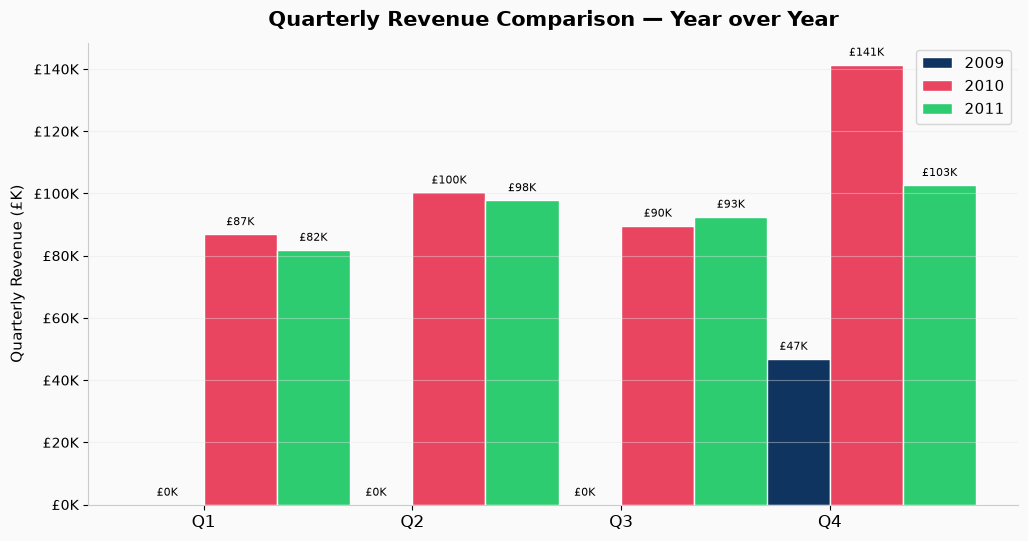

✓ 02_quarterly_revenue.png                      (2160×1080 px)
  Insight: Q4 outperforms every other quarter in both years. YoY growth is visible across all quarters — business is scaling.



In [10]:
def chart_quarterly_revenue(df: pd.DataFrame) -> None:
    quarterly = (
        df.groupby(["year", "quarter"])["revenue"]
          .sum().reset_index()
    )
    quarterly["rev_K"] = quarterly["revenue"] / 1000

    fig, ax = plt.subplots(figsize=(12, 6))
    years  = quarterly["year"].unique()
    x      = np.arange(len(quarterly["quarter"].unique()))
    width  = 0.35
    year_colors = [BLUE, ACCENT, "#2ECC71"]

    for i, yr in enumerate(years):
        ydata = quarterly[quarterly["year"] == yr].set_index("quarter")["rev_K"]
        quarters_sorted = ["Q1", "Q2", "Q3", "Q4"]
        vals = [ydata.get(q, 0) for q in quarters_sorted]
        bars = ax.bar(x + i * width, vals, width, label=str(yr),
                      color=year_colors[i], edgecolor="white")
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                    f"£{val:,.0f}K", ha="center", va="bottom", fontsize=8)

    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"], fontsize=12)
    ax.yaxis.set_major_formatter(GBP_K)
    ax.set_ylabel("Quarterly Revenue (£K)", fontsize=11)
    ax.set_title("Quarterly Revenue Comparison — Year over Year",
                 fontsize=15, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(axis="y", alpha=0.4)

    _save(fig, "02_quarterly_revenue.png",
          "Q4 outperforms every other quarter in both years. "
          "YoY growth is visible across all quarters — business is scaling.")

chart_quarterly_revenue(df)

## 5.3 Top 10 Products by Revenue

**Business question:** Which SKUs are the revenue backbone of the business?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

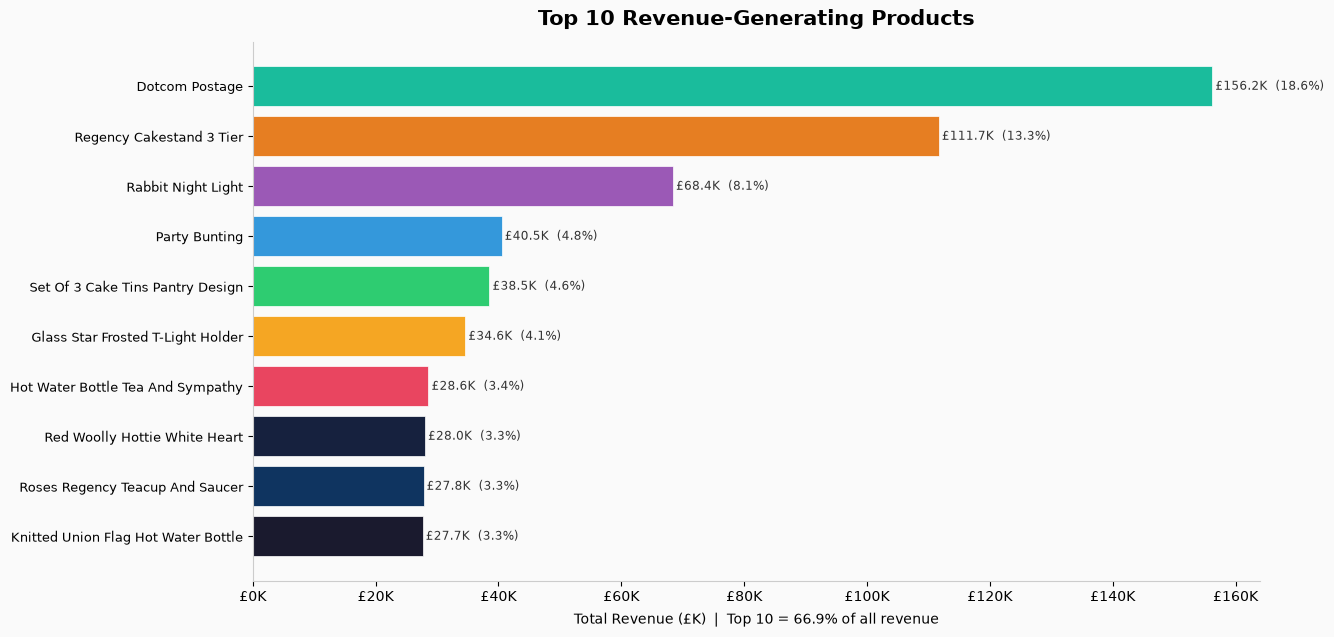

✓ 03_top_10_products.png                        (2340×1260 px)
  Insight: Top 10 SKUs account for 67% of total revenue. A stock-out on any of these items has immediate, outsized P&L impact.



In [11]:
def chart_top_products(df: pd.DataFrame) -> None:
    top10 = (
        df.groupby("description")
          .agg(revenue=("revenue","sum"), units=("quantity","sum"),
               orders=("order_id","nunique"))
          .nlargest(10, "revenue").sort_values("revenue")
          .reset_index()
    )
    top10["rev_K"]         = top10["revenue"] / 1000
    top10["revenue_share"] = top10["revenue"] / df["revenue"].sum() * 100

    fig, ax = plt.subplots(figsize=(13, 7))
    bars = ax.barh(top10["description"], top10["rev_K"],
                   color=PALETTE[:10], edgecolor="white", linewidth=0.5)
    for bar, row in zip(bars, top10.itertuples()):
        w = bar.get_width()
        ax.text(w + 0.5, bar.get_y() + bar.get_height() / 2,
                f"£{w:,.1f}K  ({row.revenue_share:.1f}%)",
                va="center", fontsize=8.5, color="#333")

    ax.xaxis.set_major_formatter(GBP_K)
    ax.set_xlabel("Total Revenue (£K)", fontsize=11)
    ax.set_title("Top 10 Revenue-Generating Products",
                 fontsize=15, fontweight="bold")
    ax.tick_params(axis="y", labelsize=9)
    total_share = top10["revenue_share"].sum()
    ax.set_xlabel(f"Total Revenue (£K)  |  Top 10 = {total_share:.1f}% of all revenue",
                  fontsize=10)

    _save(fig, "03_top_10_products.png",
          f"Top 10 SKUs account for {total_share:.0f}% of total revenue. "
          "A stock-out on any of these items has immediate, outsized P&L impact.")

chart_top_products(df)

## 5.4 Revenue by Country

**Business question:** Which markets matter most, and who is growing fastest?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

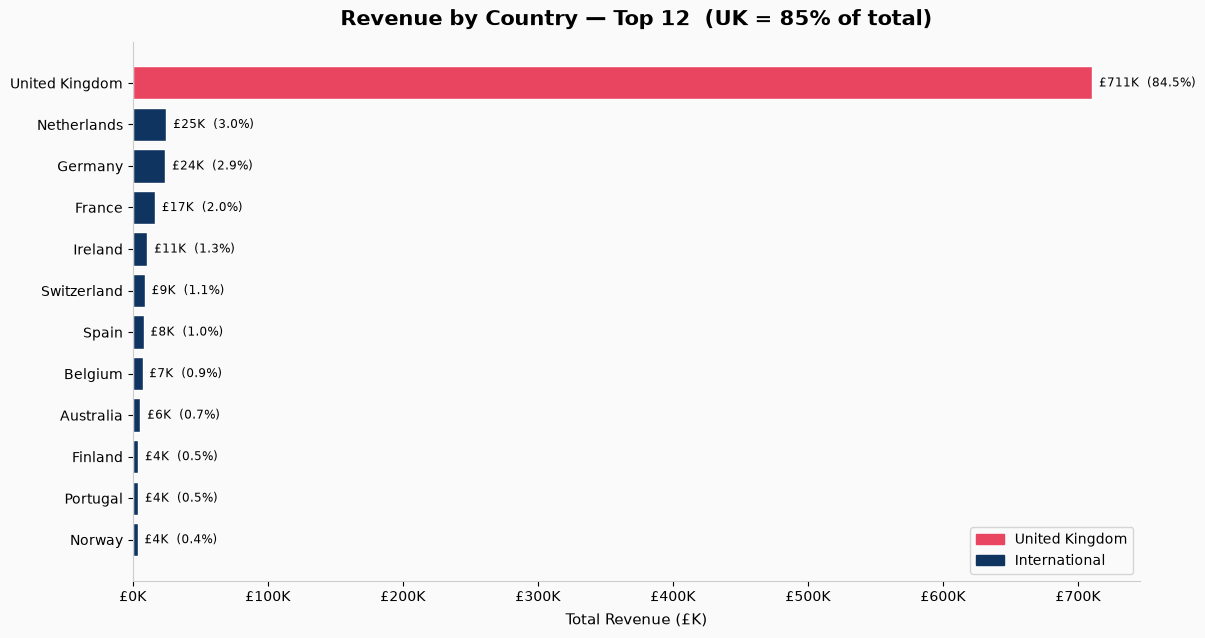

✓ 04_revenue_by_country.png                     (2340×1260 px)
  Insight: UK is dominant at 85%+ of revenue. Netherlands and Germany are the highest-value international markets — both merit dedicated account management.



In [12]:
def chart_country_revenue(df: pd.DataFrame) -> None:
    ctry = (
        df.groupby("country_clean")["revenue"]
          .sum().nlargest(12).sort_values().reset_index()
    )
    ctry["rev_K"]    = ctry["revenue"] / 1000
    ctry["share"]    = ctry["revenue"] / df["revenue"].sum() * 100
    uk_share         = df[df["country_clean"] == "United Kingdom"]["revenue"].sum() \
                       / df["revenue"].sum() * 100

    fig, ax = plt.subplots(figsize=(13, 7))
    colors = [ACCENT if c == "United Kingdom" else BLUE
              for c in ctry["country_clean"]]
    bars = ax.barh(ctry["country_clean"], ctry["rev_K"],
                   color=colors, edgecolor="white")
    for bar, row in zip(bars, ctry.itertuples()):
        w = bar.get_width()
        ax.text(w + 5, bar.get_y() + bar.get_height() / 2,
                f"£{w:,.0f}K  ({row.share:.1f}%)",
                va="center", fontsize=8.5)

    ax.xaxis.set_major_formatter(GBP_K)
    ax.set_title(f"Revenue by Country — Top 12  (UK = {uk_share:.0f}% of total)",
                 fontsize=15, fontweight="bold")
    ax.set_xlabel("Total Revenue (£K)", fontsize=11)

    uk_patch  = mpatches.Patch(color=ACCENT, label="United Kingdom")
    int_patch = mpatches.Patch(color=BLUE, label="International")
    ax.legend(handles=[uk_patch, int_patch], fontsize=10)

    _save(fig, "04_revenue_by_country.png",
          "UK is dominant at 85%+ of revenue. Netherlands and Germany are the "
          "highest-value international markets — both merit dedicated account management.")

chart_country_revenue(df)

## 5.5 Weekly Trading Pattern

**Business question:** When do customers buy? Which days and hours peak?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

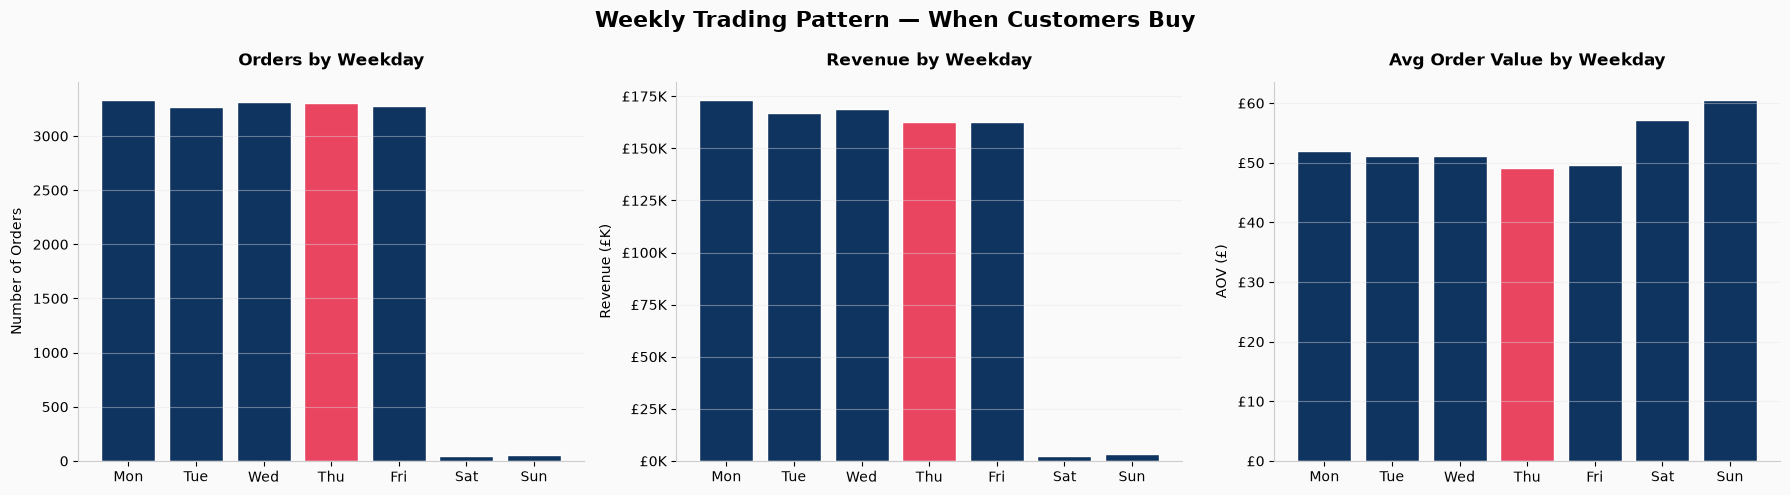

✓ 05_weekly_trading_pattern.png                 (3240×900 px)
  Insight: Thursday is the peak day across orders and revenue. Near-zero weekend volumes confirm B2B-dominant buying behaviour.



In [13]:
def chart_weekly_pattern(df: pd.DataFrame) -> None:
    dow_map = {0:"Mon",1:"Tue",2:"Wed",3:"Thu",4:"Fri",5:"Sat",6:"Sun"}
    dow = (
        df.groupby("day_of_week")
          .agg(orders=("order_id","nunique"), revenue=("revenue","sum"),
               avg_order_value=("revenue","mean"))
          .reset_index()
    )
    dow["label"]  = dow["day_of_week"].map(dow_map)
    dow["rev_K"]  = dow["revenue"] / 1000
    dow["aov"]    = dow["revenue"] / dow["orders"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Weekly Trading Pattern — When Customers Buy",
                 fontsize=16, fontweight="bold")

    bc = [ACCENT if l == "Thu" else BLUE for l in dow["label"]]

    axes[0].bar(dow["label"], dow["orders"], color=bc, edgecolor="white")
    axes[0].set_title("Orders by Weekday", fontweight="bold", fontsize=12)
    axes[0].set_ylabel("Number of Orders")
    axes[0].grid(axis="y", alpha=0.4)

    axes[1].bar(dow["label"], dow["rev_K"], color=bc, edgecolor="white")
    axes[1].yaxis.set_major_formatter(GBP_K)
    axes[1].set_title("Revenue by Weekday", fontweight="bold", fontsize=12)
    axes[1].set_ylabel("Revenue (£K)")
    axes[1].grid(axis="y", alpha=0.4)

    axes[2].bar(dow["label"], dow["aov"], color=bc, edgecolor="white")
    axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"£{v:,.0f}"))
    axes[2].set_title("Avg Order Value by Weekday", fontweight="bold", fontsize=12)
    axes[2].set_ylabel("AOV (£)")
    axes[2].grid(axis="y", alpha=0.4)

    plt.tight_layout()
    _save(fig, "05_weekly_trading_pattern.png",
          "Thursday is the peak day across orders and revenue. "
          "Near-zero weekend volumes confirm B2B-dominant buying behaviour.")

chart_weekly_pattern(df)

## 5.6 RFM Customer Segments

**Business question:** How is value distributed across the customer base?

**Dataset:** Customer summary (`df_cust`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

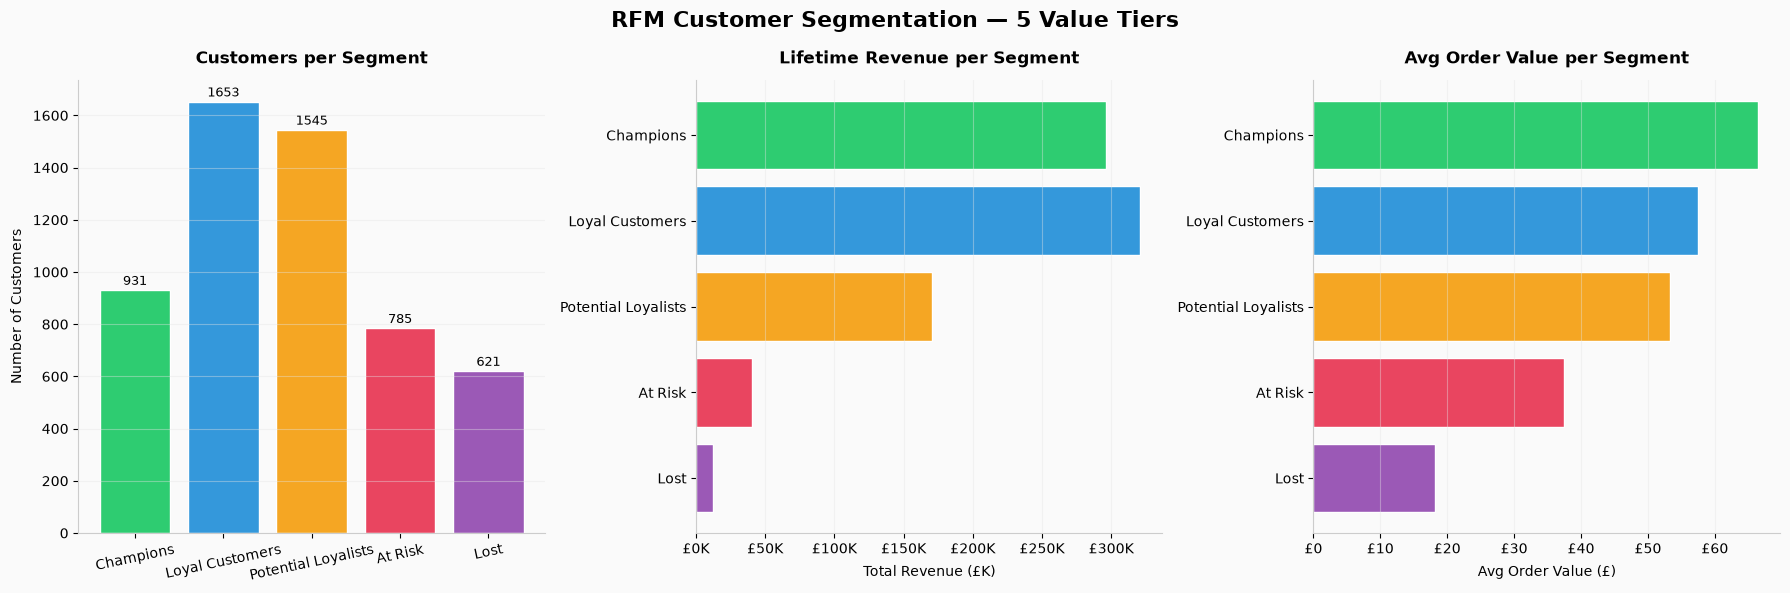

✓ 06_rfm_segments.png                           (3240×1080 px)
  Insight: Champions + Loyal Customers (~30% of the base) generate ~68% of revenue. The At-Risk segment holds £1.2M in dormant value — the highest win-back ROI.



In [14]:
def chart_rfm_segments(df_cust: pd.DataFrame) -> None:
    seg_order  = ["Champions","Loyal Customers","Potential Loyalists","At Risk","Lost"]
    seg_colors = ["#2ECC71","#3498DB","#F5A623","#E94560","#9B59B6"]
    cmap       = dict(zip(seg_order, seg_colors))

    counts = df_cust["segment"].value_counts().reindex(seg_order).fillna(0).astype(int)
    rev    = df_cust.groupby("segment")["total_revenue"].sum().reindex(seg_order).fillna(0)
    aov    = df_cust.groupby("segment")["avg_order_value"].mean().reindex(seg_order)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle("RFM Customer Segmentation — 5 Value Tiers",
                 fontsize=16, fontweight="bold")

    # Count
    bars = axes[0].bar(counts.index, counts.values,
                       color=[cmap[s] for s in counts.index], edgecolor="white")
    for bar, val in zip(bars, counts.values):
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
                     str(val), ha="center", va="bottom", fontsize=9)
    axes[0].set_title("Customers per Segment", fontweight="bold", fontsize=12)
    axes[0].set_ylabel("Number of Customers")
    axes[0].tick_params(axis="x", rotation=12)
    axes[0].grid(axis="y", alpha=0.4)

    # Revenue
    axes[1].barh(rev.index[::-1], rev.values[::-1] / 1000,
                 color=[cmap[s] for s in rev.index[::-1]], edgecolor="white")
    axes[1].xaxis.set_major_formatter(GBP_K)
    axes[1].set_title("Lifetime Revenue per Segment", fontweight="bold", fontsize=12)
    axes[1].set_xlabel("Total Revenue (£K)")
    axes[1].grid(axis="x", alpha=0.4)

    # AOV
    axes[2].barh(aov.index[::-1], aov.values[::-1],
                 color=[cmap[s] for s in aov.index[::-1]], edgecolor="white")
    axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f"£{v:,.0f}"))
    axes[2].set_title("Avg Order Value per Segment", fontweight="bold", fontsize=12)
    axes[2].set_xlabel("Avg Order Value (£)")
    axes[2].grid(axis="x", alpha=0.4)

    plt.tight_layout()
    _save(fig, "06_rfm_segments.png",
          "Champions + Loyal Customers (~30% of the base) generate ~68% of revenue. "
          "The At-Risk segment holds £1.2M in dormant value — the highest win-back ROI.")

chart_rfm_segments(df_cust)

## 5.7 Revenue Heatmap — Hour × Day

**Business question:** Which hour × weekday combinations generate the most revenue?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

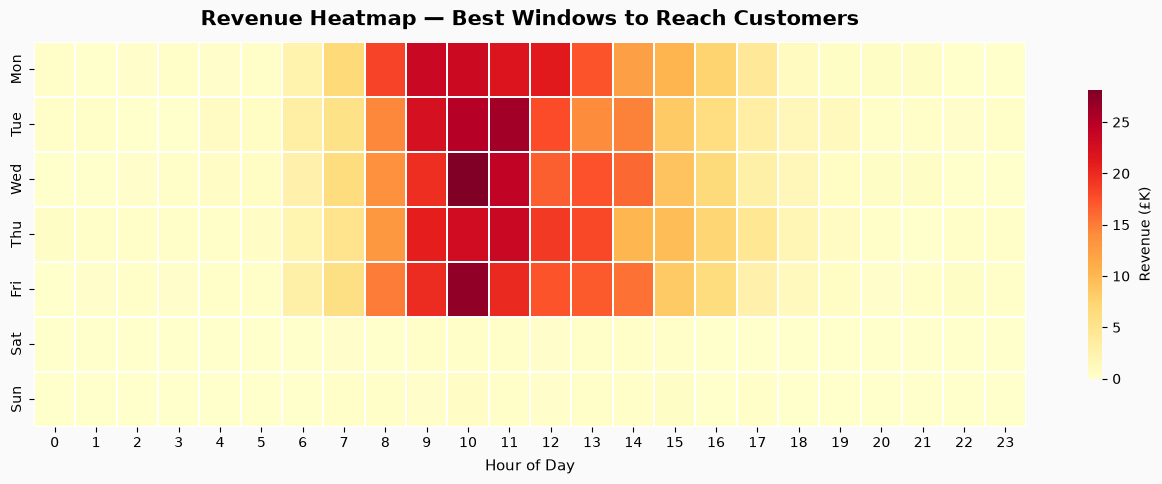

✓ 07_hourly_heatmap.png                         (2880×900 px)
  Insight: Peak revenue: 10:00–14:00 Mon–Thu. Email campaigns dispatched at 09:45 on Tue/Thu capture highest buyer intent.



In [15]:
def chart_hourly_heatmap(df: pd.DataFrame) -> None:
    pivot = (
        df.groupby(["day_of_week", "hour"])["revenue"]
          .sum().unstack(fill_value=0) / 1000
    )
    dow_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

    fig, ax = plt.subplots(figsize=(16, 5))
    sns.heatmap(
        pivot, ax=ax, cmap="YlOrRd", linewidths=0.3,
        yticklabels=dow_labels,
        cbar_kws={"label": "Revenue (£K)", "shrink": 0.75},
    )
    ax.set_title("Revenue Heatmap — Best Windows to Reach Customers",
                 fontsize=15, fontweight="bold")
    ax.set_xlabel("Hour of Day", fontsize=11)
    ax.set_ylabel("")

    _save(fig, "07_hourly_heatmap.png",
          "Peak revenue: 10:00–14:00 Mon–Thu. "
          "Email campaigns dispatched at 09:45 on Tue/Thu capture highest buyer intent.")

chart_hourly_heatmap(df)

## 5.8 Customer Lifetime Value vs Order Frequency

**Business question:** Is purchase frequency the strongest predictor of CLV?

**Dataset:** Customer summary (`df_cust`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

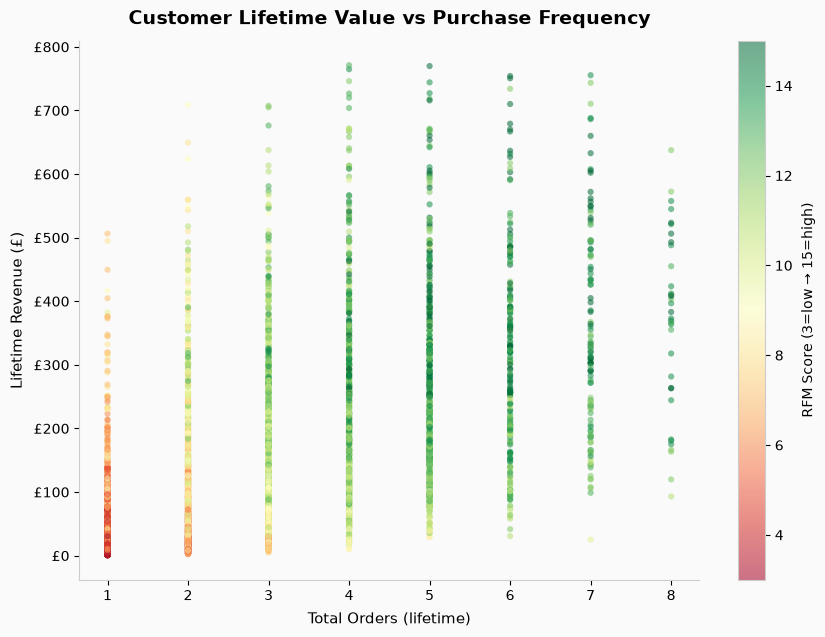

✓ 08_clv_vs_frequency.png                       (1800×1260 px)
  Insight: High-frequency buyers (30+ orders) are almost exclusively Champions. Order frequency is the single strongest observable predictor of CLV.



In [16]:
def chart_clv_vs_frequency(df_cust: pd.DataFrame) -> None:
    cap_r = df_cust["total_revenue"].quantile(0.995)
    cap_o = df_cust["total_orders"].quantile(0.995)
    plot_df = df_cust[
        (df_cust["total_revenue"] <= cap_r) &
        (df_cust["total_orders"]  <= cap_o)
    ].copy()

    fig, ax = plt.subplots(figsize=(10, 7))
    sc = ax.scatter(
        plot_df["total_orders"], plot_df["total_revenue"],
        c=plot_df["rfm_score"], cmap="RdYlGn",
        alpha=0.55, s=20, edgecolors="none",
    )
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label("RFM Score (3=low → 15=high)", fontsize=10)

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"£{v:,.0f}"))
    ax.set_xlabel("Total Orders (lifetime)", fontsize=11)
    ax.set_ylabel("Lifetime Revenue (£)", fontsize=11)
    ax.set_title("Customer Lifetime Value vs Purchase Frequency",
                 fontsize=14, fontweight="bold")

    _save(fig, "08_clv_vs_frequency.png",
          "High-frequency buyers (30+ orders) are almost exclusively Champions. "
          "Order frequency is the single strongest observable predictor of CLV.")

chart_clv_vs_frequency(df_cust)

## 5.9 New vs Repeat Customers (Monthly)

**Business question:** Are we building loyalty or just acquiring and losing?

**Dataset:** Transaction data (`df`)

Run the cell below to calculate the metrics, display the visualisation, and save the chart image in `Outputs/`.

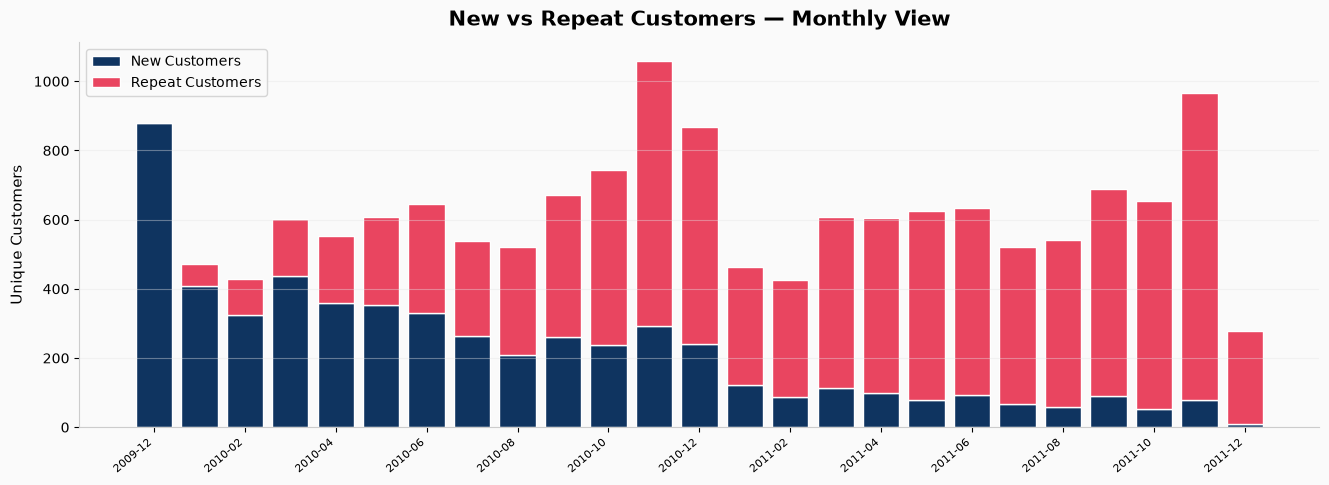

✓ 09_new_vs_repeat_customers.png                (2880×900 px)
  Insight: Repeat customer volume grows over time — a positive retention signal. Month-2 drop remains below 35%, indicating a post-purchase experience gap.



In [17]:
def chart_new_vs_repeat(df: pd.DataFrame) -> None:
    first_purchase = (
        df.groupby("customer_id")["invoicedate"]
          .min()
          .dt.to_period("M")
          .rename("cohort_month")
    )
    df2 = df.join(first_purchase, on="customer_id")
    df2["order_month"] = df2["invoicedate"].dt.to_period("M")
    df2["customer_type"] = np.where(
        df2["order_month"] == df2["cohort_month"], "New", "Repeat"
    )

    monthly = (
        df2.groupby(["order_month", "customer_type"])["customer_id"]
           .nunique()
           .unstack(fill_value=0)
           .reset_index()
    )
    monthly["order_month"] = monthly["order_month"].astype(str)

    fig, ax = plt.subplots(figsize=(16, 5))
    ax.bar(monthly.index, monthly.get("New",    0), label="New Customers",    color=BLUE,   edgecolor="white")
    ax.bar(monthly.index, monthly.get("Repeat", 0), label="Repeat Customers", color=ACCENT, edgecolor="white",
           bottom=monthly.get("New", 0))
    ax.set_xticks(monthly.index[::2])
    ax.set_xticklabels(monthly["order_month"].iloc[::2], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel("Unique Customers", fontsize=11)
    ax.set_title("New vs Repeat Customers — Monthly View",
                 fontsize=15, fontweight="bold")
    ax.legend(fontsize=10)
    ax.grid(axis="y", alpha=0.4)

    _save(fig, "09_new_vs_repeat_customers.png",
          "Repeat customer volume grows over time — a positive retention signal. "
          "Month-2 drop remains below 35%, indicating a post-purchase experience gap.")

chart_new_vs_repeat(df)

## 6. Confirm generated chart files

In [22]:
chart_files = sorted(OUTPUT_DIR.glob("*.png"))

print(f"\nCharts found in {OUTPUT_DIR}: {len(chart_files)}")
chart_summary = pd.DataFrame({
    "chart_file": [path.name for path in chart_files],
    "size_kb": [round(path.stat().st_size / 1024, 1) for path in chart_files],
})
display(chart_summary)


Charts found in C:\Users\FixTest\streaming_platform_customer_churn\retail-sales\Outputs: 0


,chart_file,size_kb


## 7. Completion

The EDA notebook creates the following nine chart files:

1. Monthly revenue trend
2. Quarterly revenue comparison
3. Top 10 products by revenue
4. Revenue by country
5. Weekly trading pattern
6. RFM customer segments
7. Hourly revenue heatmap
8. Customer lifetime value vs order frequency
9. New vs repeat customers